# Homework 2 · Problem 3: Random Kitchen Sinks vs. a 1-hidden-layer MLP

**Files needed in this folder:** `train.csv`, `val.csv`, `test.csv`, `dataloader.py`, `plotting.py` (all provided) and the
completed `models.py` that comes with this solution (it fills in the provided skeleton; same class and function names).

**To run:** `pip install torch numpy pandas matplotlib`, then *Run All*. Everything runs on a CPU in a few minutes.

Outputs written to this folder: `rks_test_predictions.csv`, `mlp_test_predictions.csv`, and the figures
`train_data.png`, `rks_sweep.png`, `mlp_sweep.png`, `rks_surface.png`, `mlp_surface.png`.

## Setup

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from dataloader import HW2Dataset
from models import RandomKitchenSinks, sweep_rks_model, MLP, mlp_sweep, mse
from plotting import plot_surface_2d


ds = HW2Dataset.from_csv("train.csv", "val.csv", "test.csv")
X_train, y_train = ds.train.X, ds.train.y
X_val, y_val = ds.val.X, ds.val.y
X_test = ds.test.X
print("train", X_train.shape, "val", X_val.shape, "test", X_test.shape)

train (600, 2) val (200, 2) test (200, 2)


## (a) Data visualization

> Begin by visualizing the training data. The dataset corresponds to samples $(x_1, x_2, y)$ and you can be assured that
> $(x_1, x_2)$ are each bounded between $[-3, 3]$. You can either generate a 2D grid-plot where the $y$ value is
> represented by a color at different $(x_1, x_2)$ locations, or a 3D plot where we visualize the response $y$ on the z-axis.

We draw both: a 2D scatter coloured by $y$, and a 3D scatter.

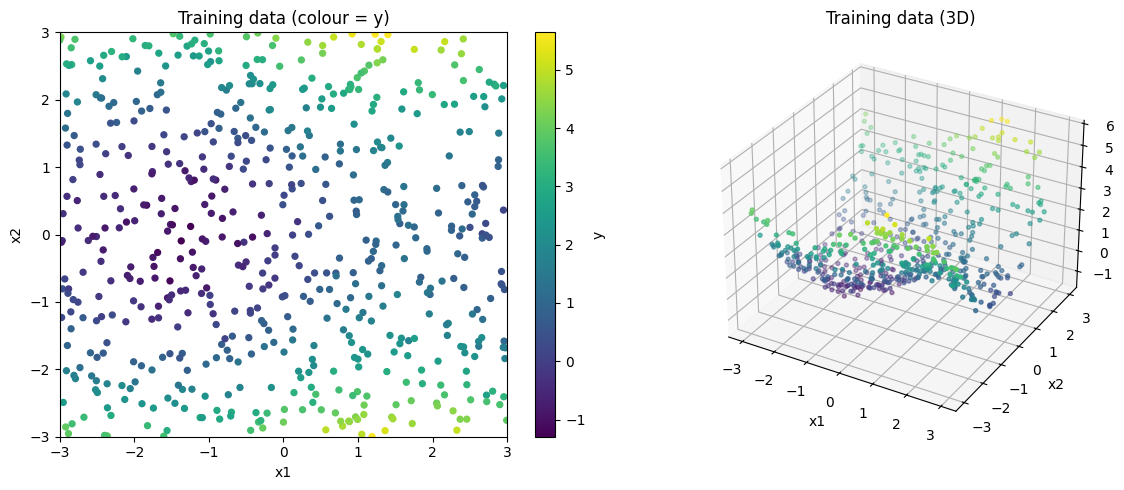

y: mean 1.533, variance 2.463, range [-1.30, 5.64]


In [19]:
fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(1, 2, 1)
sc = ax1.scatter(X_train[:, 0], X_train[:, 1], c=y_train, s=18, cmap="viridis")
fig.colorbar(sc, ax=ax1, label="y")
ax1.set(xlim=(-3, 3), ylim=(-3, 3), xlabel="x1", ylabel="x2", title="Training data (colour = y)")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.scatter(X_train[:, 0], X_train[:, 1], y_train, c=y_train, s=8, cmap="viridis")
ax2.set(xlabel="x1", ylabel="x2", zlabel="y", title="Training data (3D)")
plt.tight_layout()
plt.savefig("train_data.png", dpi=150)
plt.show()

print(f"y: mean {y_train.mean():.3f}, variance {y_train.var():.3f}, range [{y_train.min():.2f}, {y_train.max():.2f}]")

**What we see.** $y$ is a smooth surface: it is lowest around $(x_1, x_2) \approx (-1.6, 0)$, rises towards the
top and bottom edges ($|x_2|$ large), and is highest near $(1.5, \pm 3)$. Neighbouring points have similar colours, so
the noise is small compared with the signal. A linear model cannot capture this bowl-and-ridge shape, so we need
non-linear features.

Two reference baselines (any model should beat these): predicting the training mean, and ordinary linear regression on $(x_1, x_2)$.

In [20]:
mse_const = mse(y_val, np.full_like(y_val, y_train.mean()))
A_train = np.c_[np.ones(len(X_train)), X_train]
coef_lin = np.linalg.lstsq(A_train, y_train, rcond=None)[0]
mse_lin = mse(y_val, np.c_[np.ones(len(X_val)), X_val] @ coef_lin)
print(f"baseline: constant (train mean)   val MSE {mse_const:.4f}")
print(f"baseline: linear regression       val MSE {mse_lin:.4f}")

baseline: constant (train mean)   val MSE 2.3966
baseline: linear regression       val MSE 2.0593


## (b) Random Kitchen Sinks with ridge regression

> Implement and fit an RKS model to the given dataset with ridge regression. You will need to vary one of the key
> hyperparameters while keeping others fixed at reasonable defaults. [...] Perform a hyperparameter sweep over your chosen
> parameter and record both the training and validation losses (MSE). Plot the losses as a function of the
> hyperparameter (two plots, one for training and one for validation loss), and select the best hyper-param based on
> the validation loss.



In [21]:
sweep_D = [2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048]
RKS_SIGMA, RKS_LAMBDA = 1.0, 1e-3
best_rks, best_rks_val, best_D, rks_hist = sweep_rks_model(
    sweep_D, X_train, y_train, X_val, y_val, sigma=RKS_SIGMA, ridge_lambda=RKS_LAMBDA)
rks_table = pd.DataFrame(rks_hist).set_index("D")
print(rks_table.round(4).to_string())
print(f"\nbest D = {best_D} (h = {best_D // 2}), validation MSE {best_rks_val:.4f}")

      train_mse  val_mse
D                       
2        1.9637   1.7835
4        0.2845   0.2555
8        0.3282   0.3231
16       0.1520   0.1561
32       0.0322   0.0368
64       0.0310   0.0373
128      0.0302   0.0393
256      0.0294   0.0410
512      0.0291   0.0443
1024     0.0288   0.0441
2048     0.0283   0.0459

best D = 32 (h = 16), validation MSE 0.0368


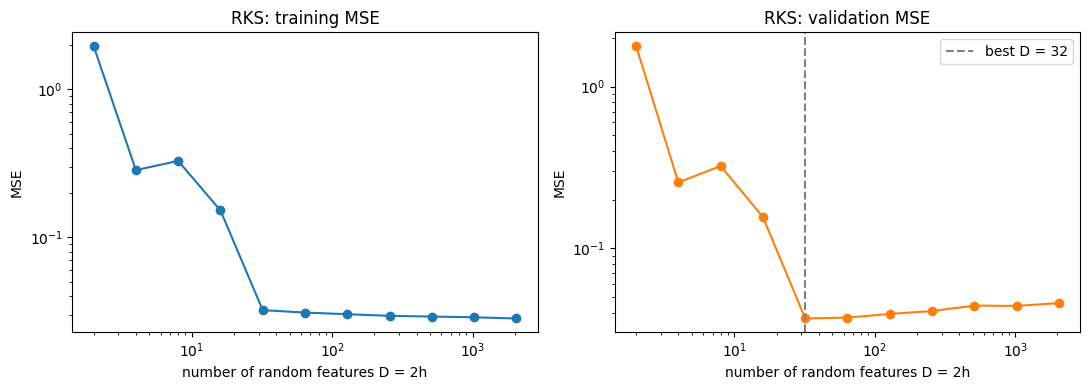

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(rks_table.index, rks_table["train_mse"], "o-")
axes[0].set(xscale="log", yscale="log", xlabel="number of random features D = 2h", ylabel="MSE",
            title="RKS: training MSE")
axes[1].plot(rks_table.index, rks_table["val_mse"], "o-", color="C1")
axes[1].axvline(best_D, ls="--", color="grey", label=f"best D = {best_D}")
axes[1].set(xscale="log", yscale="log", xlabel="number of random features D = 2h", ylabel="MSE",
            title="RKS: validation MSE")
axes[1].legend()
plt.tight_layout()
plt.savefig("rks_sweep.png", dpi=150)
plt.show()

Training MSE goes down as $D$ grows: more features means a bigger function class, and ridge
with $\lambda = 10^{-3}$ barely restrains it. Validation MSE is U-shaped. With very few features (left) the model
**underfits** (high bias): a handful of random sinusoids cannot form the surface, and which few directions were
drawn matters a lot, so this part of the curve is bumpy. In the middle the validation MSE
reaches its minimum, close to the training MSE (roughly the noise level). With many features (right) the model starts
to fit noise, and the gap between training and validation MSE grows. We pick the
$D$ with the smallest validation MSE.

## (c) 1-hidden-layer MLP

> Next, fit the same dataset using a one-hidden-layer MLP implemented in PyTorch or Jax (the provided starter code is in
> PyTorch). As before, you will choose one hyperparameter to vary (for example, the hidden layer dimension, learning rate,
> or batch size) and keep other hyperparameters fixed at default values. Plot the training and validation losses over the
> sweep and determine the best-performing configuration based on the validation loss.



In [23]:
sweep_hidden = [2, 4, 8, 16, 32, 64, 128, 256, 512]
MLP_FIXED = dict(lr=1e-2, batch_size=64, num_epochs=1000, activation="relu")
best_mlp, best_mlp_val, best_h, mlp_hist = mlp_sweep(sweep_hidden, X_train, y_train, X_val, y_val, **MLP_FIXED)
mlp_table = pd.DataFrame(mlp_hist).set_index("d_hidden")
print(f"\nbest d_hidden = {best_h}, validation MSE {best_mlp_val:.4f}")

d_hidden=   2  train MSE 0.2892  val MSE 0.2928
d_hidden=   4  train MSE 0.2891  val MSE 0.2923
d_hidden=   8  train MSE 0.0481  val MSE 0.0519
d_hidden=  16  train MSE 0.0337  val MSE 0.0442
d_hidden=  32  train MSE 0.0347  val MSE 0.0459
d_hidden=  64  train MSE 0.0332  val MSE 0.0454
d_hidden= 128  train MSE 0.0357  val MSE 0.0471
d_hidden= 256  train MSE 0.0368  val MSE 0.0498
d_hidden= 512  train MSE 0.0362  val MSE 0.0479

best d_hidden = 16, validation MSE 0.0442


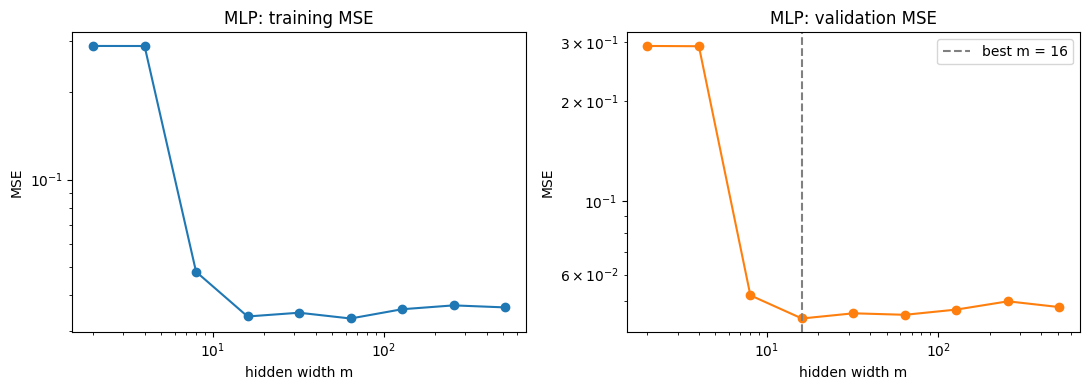

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(mlp_table.index, mlp_table["train_mse"], "o-")
axes[0].set(xscale="log", yscale="log", xlabel="hidden width m", ylabel="MSE", title="MLP: training MSE")
axes[1].plot(mlp_table.index, mlp_table["val_mse"], "o-", color="C1")
axes[1].axvline(best_h, ls="--", color="grey", label=f"best m = {best_h}")
axes[1].set(xscale="log", yscale="log", xlabel="hidden width m", ylabel="MSE", title="MLP: validation MSE")
axes[1].legend()
plt.tight_layout()
plt.savefig("mlp_sweep.png", dpi=150)
plt.show()

## (d) Comparison and visualization

> Using the best-performing hyperparameters from the previous steps, refit both models and report the validation loss
> (MSE) of each. Discuss which approach performs better and why. The provided test.csv is unlabeled (it contains only
> $x_1, x_2$): produce predictions from both models on it and submit them as two CSV files, rks_test_predictions.csv and
> mlp_test_predictions.csv, one prediction per row in the same order as test.csv. Finally, visualize the fitted functions
> from the two models over the input space (we provide an example function to do this). Compare these surfaces with your
> visualization of the training data from part (a), and qualitatively explain how each model captures the underlying
> structure of the data.

Refit on the training set with the selected hyperparameters.

In [25]:
rks_final = RandomKitchenSinks(D=best_D, sigma=RKS_SIGMA, ridge_lambda=RKS_LAMBDA, seed=0).fit(X_train, y_train)
mlp_final = MLP(d_in=2, d_hidden=best_h, **MLP_FIXED).fit(X_train, y_train)

results = pd.DataFrame({
    "model": ["constant baseline", "linear baseline", f"RKS (D = {best_D})", f"MLP (m = {best_h})"],
    "train MSE": [mse(y_train, np.full_like(y_train, y_train.mean())), mse(y_train, A_train @ coef_lin),
                  mse(y_train, rks_final.predict(X_train)), mse(y_train, mlp_final.predict(X_train))],
    "validation MSE": [mse_const, mse_lin, mse(y_val, rks_final.predict(X_val)), mse(y_val, mlp_final.predict(X_val))],
}).set_index("model")
results.round(4)

,train MSE,validation MSE
model,,
constant baseline,2.4633,2.3966
linear baseline,2.1635,2.0593
RKS (D = 32),0.0322,0.0368
MLP (m = 16),0.0337,0.0442


In [26]:
rks_test = rks_final.predict(X_test).reshape(-1)
mlp_test = mlp_final.predict(X_test).reshape(-1)
assert len(rks_test) == len(mlp_test) == len(X_test)
pd.DataFrame({"prediction": rks_test}).to_csv("rks_test_predictions.csv", index=False)
pd.DataFrame({"prediction": mlp_test}).to_csv("mlp_test_predictions.csv", index=False)
print("wrote rks_test_predictions.csv and mlp_test_predictions.csv,", len(X_test), "rows each, same order as test.csv")

wrote rks_test_predictions.csv and mlp_test_predictions.csv, 200 rows each, same order as test.csv


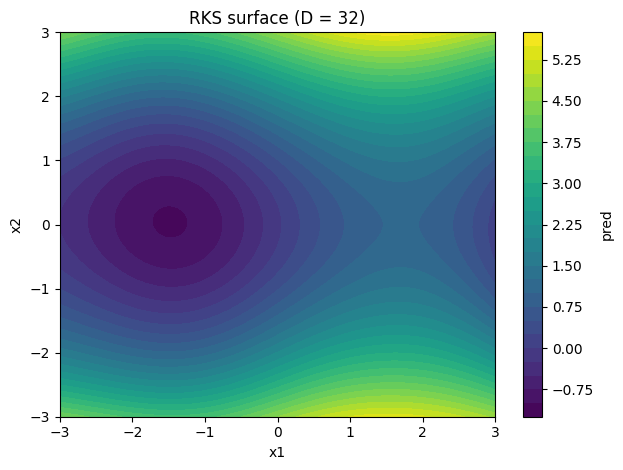

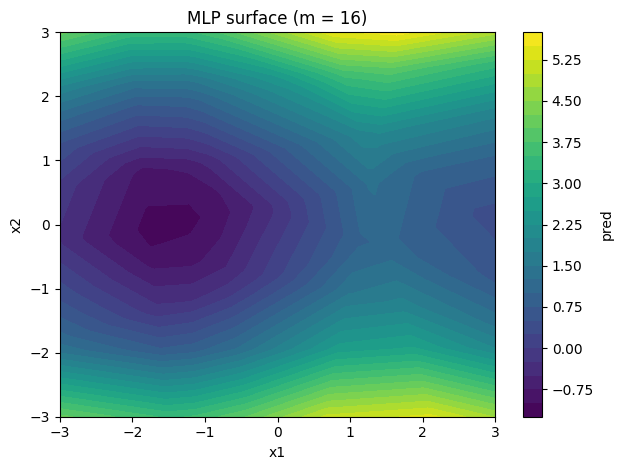

In [27]:
plot_surface_2d(rks_final.predict, (-3, 3), (-3, 3), title=f"RKS surface (D = {best_D})", filename="rks_surface.png")
plt.show()
plot_surface_2d(mlp_final, (-3, 3), (-3, 3), title=f"MLP surface (m = {best_h})", filename="mlp_surface.png")
plt.show()

Interpretation.

Both RKS and MLP significantly outperform the baselines and achieve validation MSE close to the noise level, with RKS performing slightly better (0.037 vs. 0.04). RKS works well because the target is smooth and low-dimensional, and ridge regression provides an exact convex solution, while MLP training depends on optimization settings. Both models capture the main surface patterns, but RKS produces a smoother surface and is less likely to fit noise, whereas the ReLU MLP is piecewise linear and more flexible. Near the boundaries, RKS remains bounded while the MLP extrapolates linearly.